Reading power logs from: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/power_logs/gpt2
Saving plots to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2
tp1_pp1_dp4: avg=553.5W  steady_avg=647.0W  peak=706.7W  samples=505
tp4_pp1_dp1: avg=453.1W  steady_avg=481.6W  peak=502.4W  samples=1215
tp1_pp4_dp1: avg=462.9W  steady_avg=505.6W  peak=540.6W  samples=834
tp2_pp2_dp1: avg=445.6W  steady_avg=476.5W  peak=500.2W  samples=1075
tp2_pp1_dp2: avg=505.4W  steady_avg=568.1W  peak=599.7W  samples=712
tp1_pp2_dp2: avg=492.5W  steady_avg=555.7W  peak=583.0W  samples=690
hybrid_schedule [SCHEDULE]: avg=663.6W  steady_avg=750.6W  peak=936.0W  samples=895

Label                     |    Time |   Power |   Energy |  C_fixed |   C_vary |       Tput
-----------------------------------------------------------------------------------------------
DP=4 (TP=1,PP=1)          |  252.5s |  553.5W |   38.82Wh |  15.53g |  29.88g |  12977.4 tok/s
TP=4 (PP=1,DP

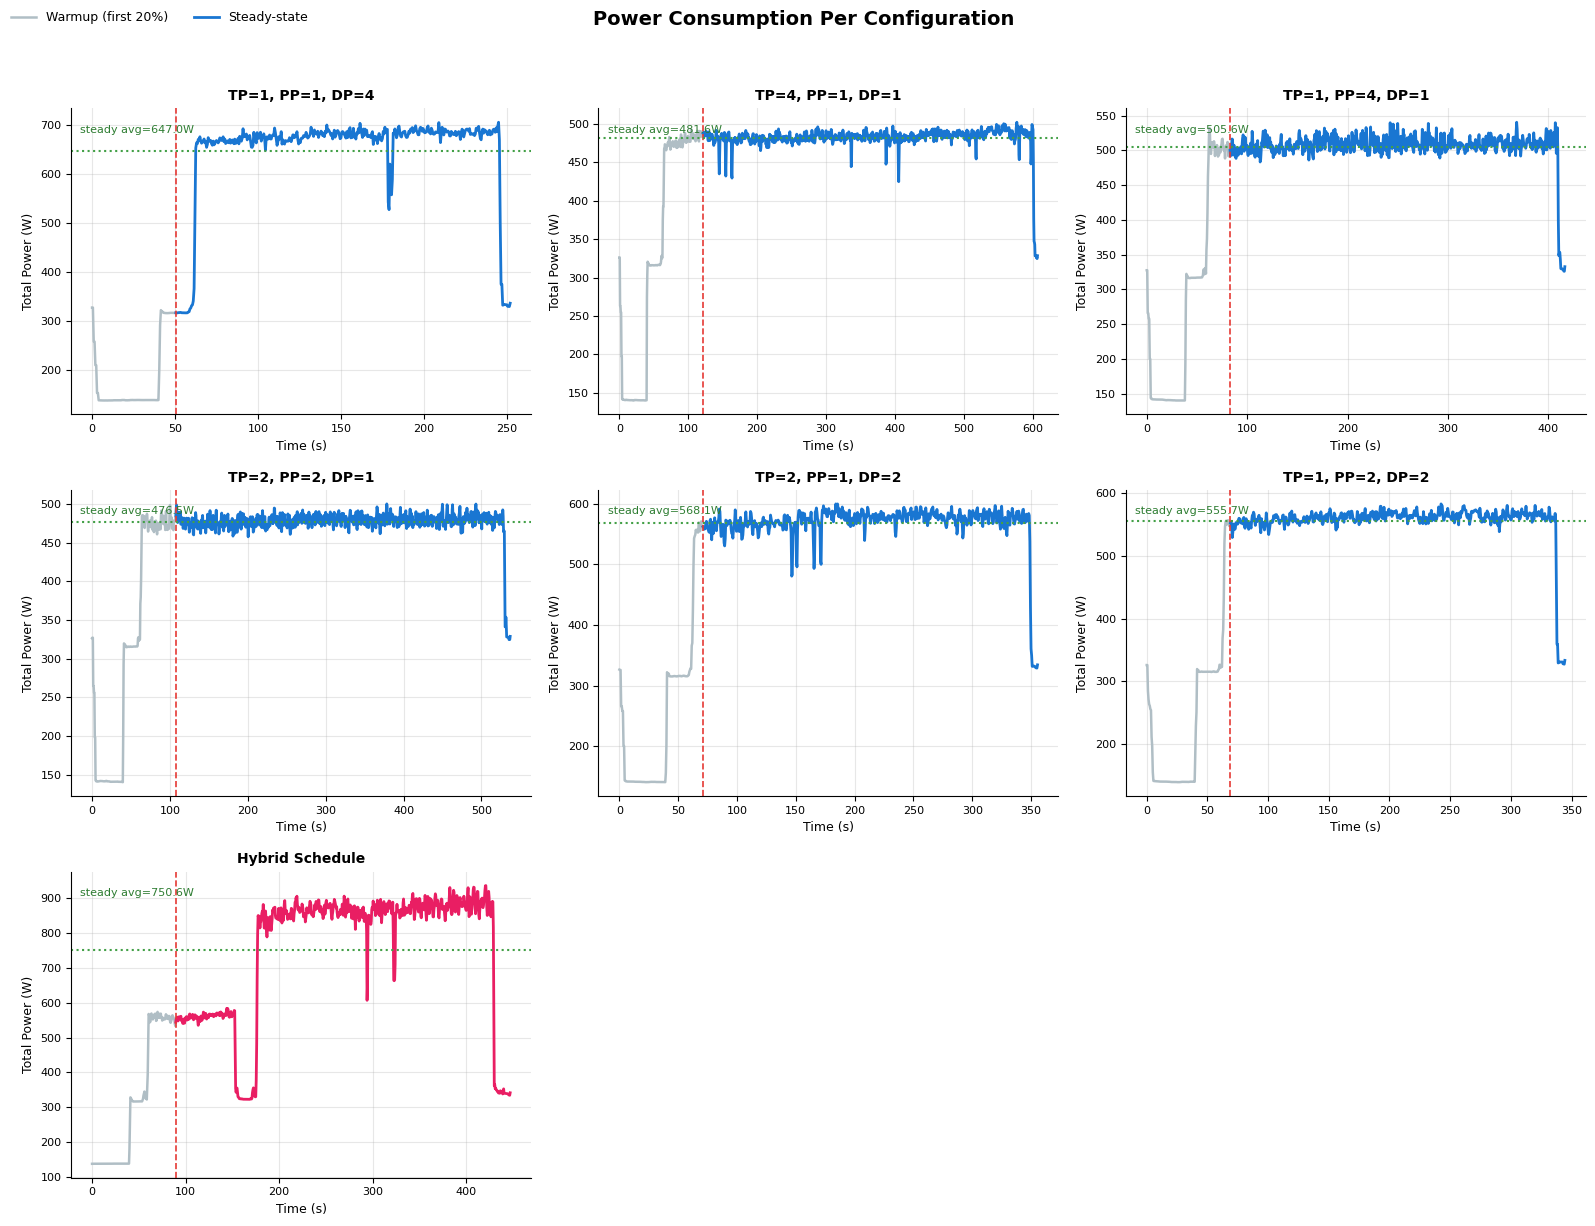

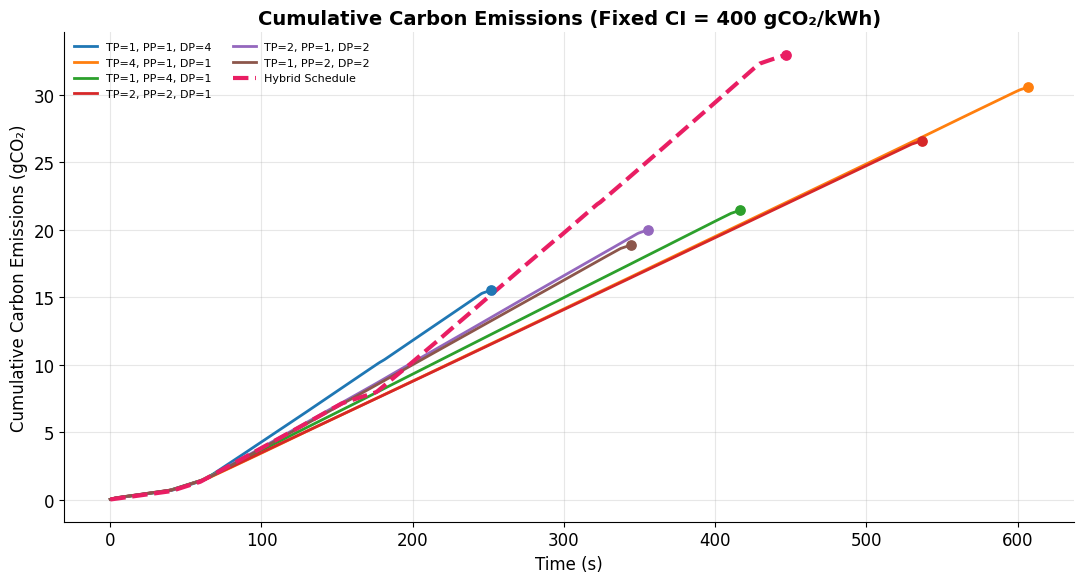


CARBON SCHEDULE (wall-clock-based):
  A = [1000, 50, 50] gCO₂/kWh over 600s
  Period 1: 0–200s → 1000 g/kWh (high)
  Period 2: 200–400s → 50 g/kWh (low)
  Period 3: 400–600s → 50 g/kWh (low)
Fixed baseline: 400 gCO₂/kWh

Config                    |   Time |   Fixed CI | Varying CI |        Δ
----------------------------------------------------------------------
TP=1,PP=1,DP=4            |   252s |    15.53 g |    29.88 g |  +92.4%
TP=4,PP=1,DP=1            |   608s |    30.58 g |    24.64 g |  -19.4%
TP=1,PP=4,DP=1            |   417s |    21.45 g |    24.70 g |  +15.2%
TP=2,PP=2,DP=1            |   538s |    26.61 g |    24.10 g |   -9.5%
TP=2,PP=1,DP=2            |   356s |    19.99 g |    26.58 g |  +33.0%
TP=1,PP=2,DP=2            |   345s |    18.88 g |    26.04 g |  +37.9%
Hybrid Schedule           |   448s |    33.00 g |    28.27 g |  -14.3%


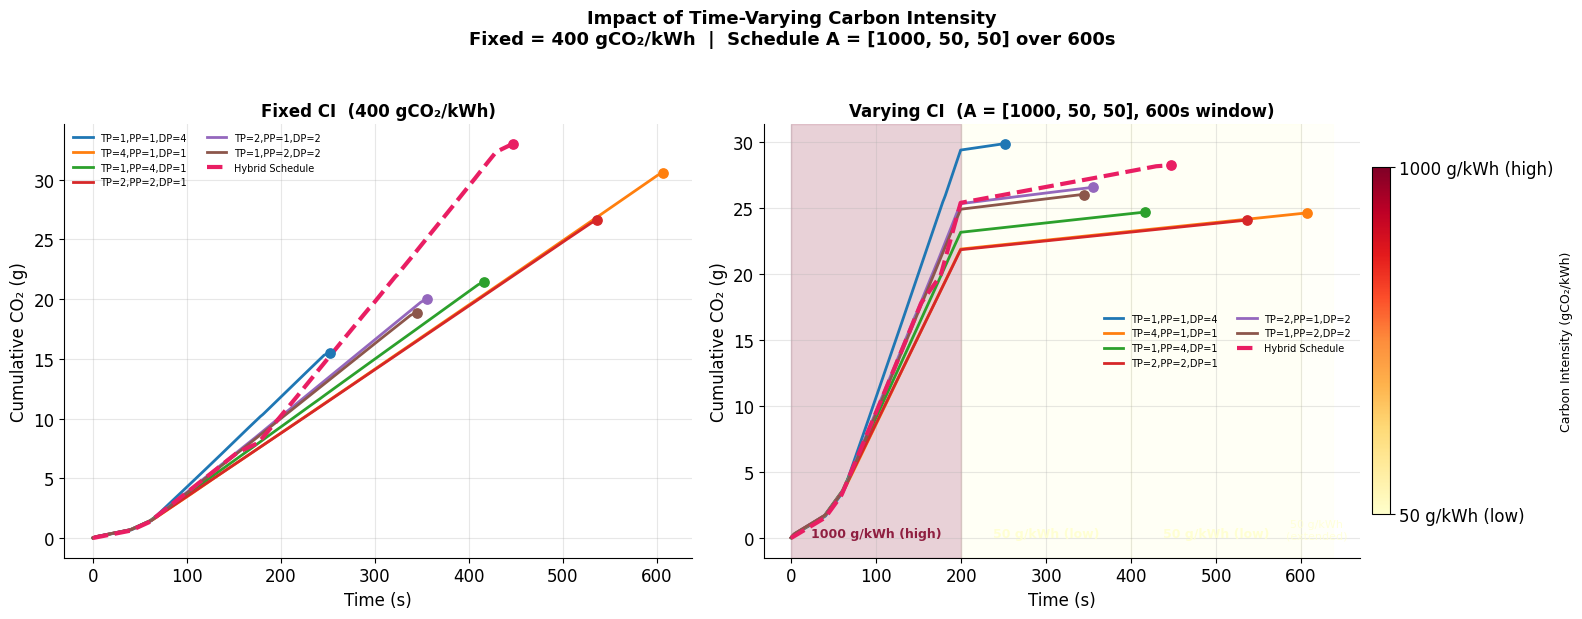

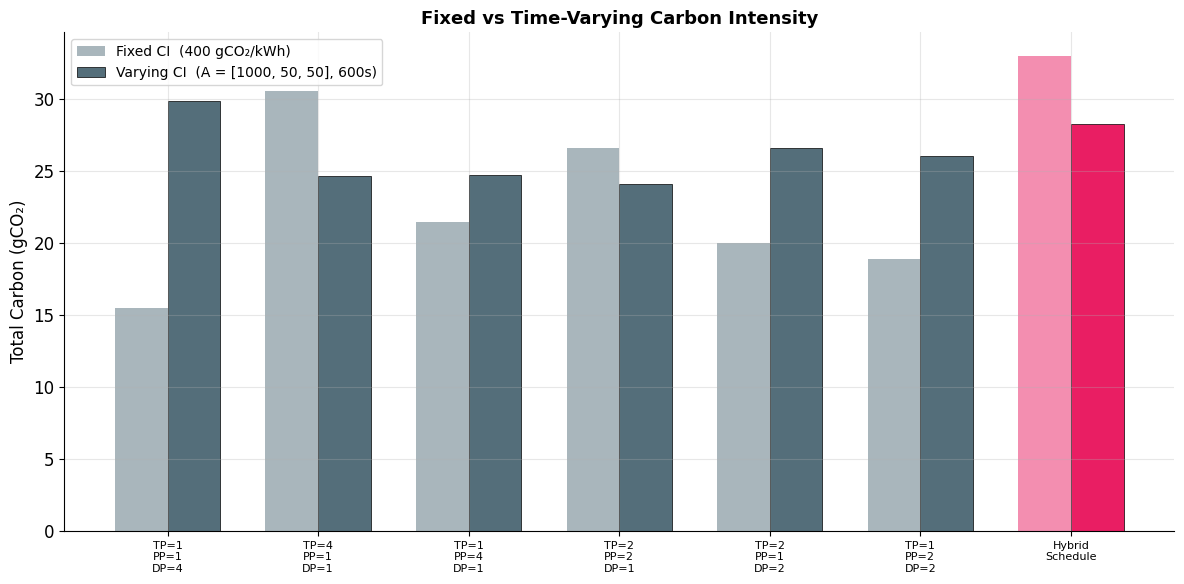


Optimal carbon-aware schedule for A = [1000, 50, 50]:
  Period 1 (1000 g/kWh (high)) → tp2_pp2_dp1 (low power — minimize emissions during dirty grid)
  Period 2 (50 g/kWh (low)) → tp1_pp1_dp4 (max throughput — finish quickly during clean grid)
  Period 3 (50 g/kWh (low)) → tp1_pp1_dp4 (max throughput — finish quickly during clean grid)


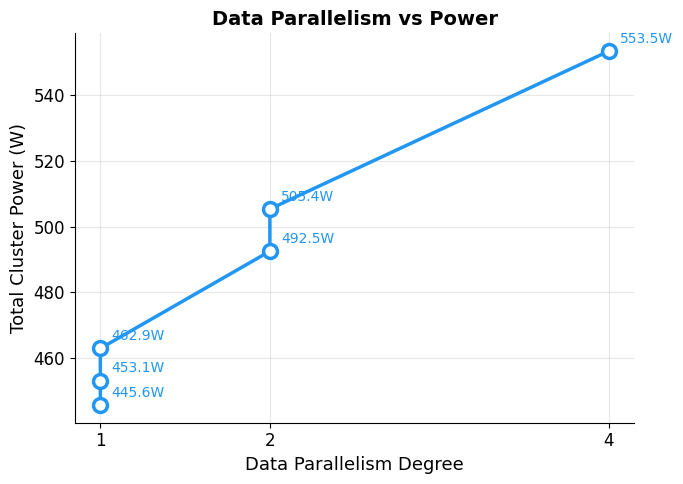

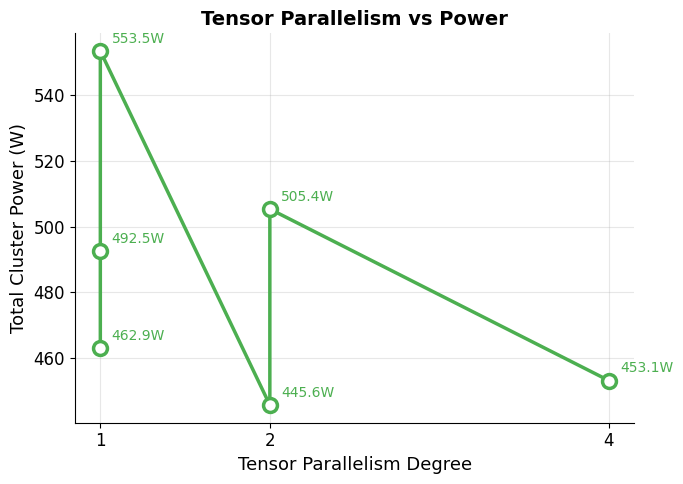

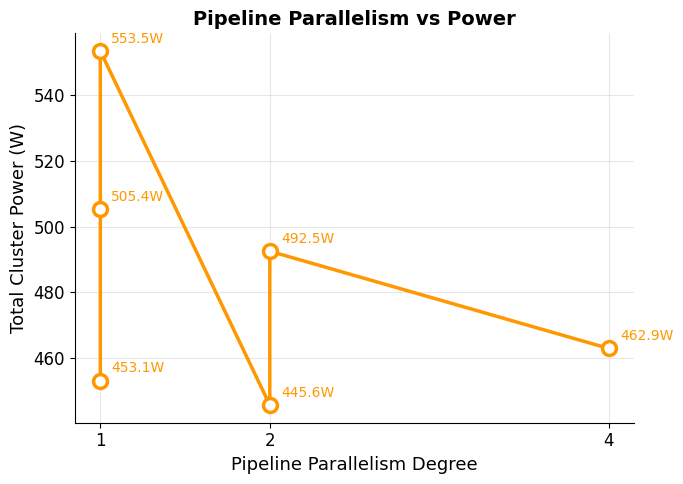

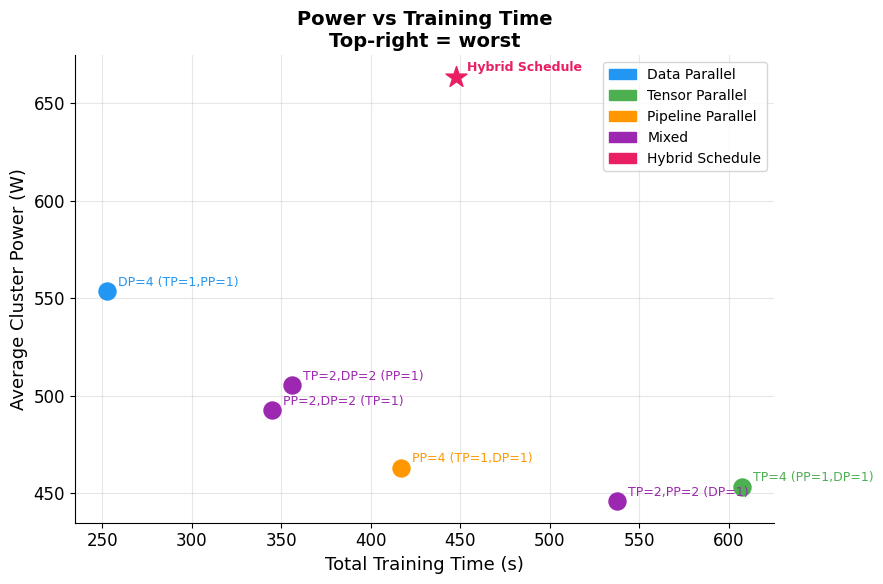

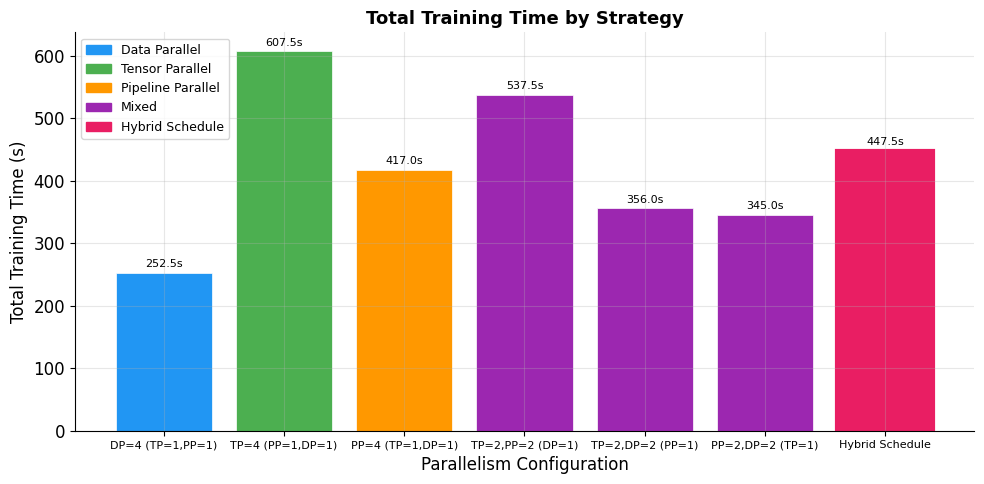

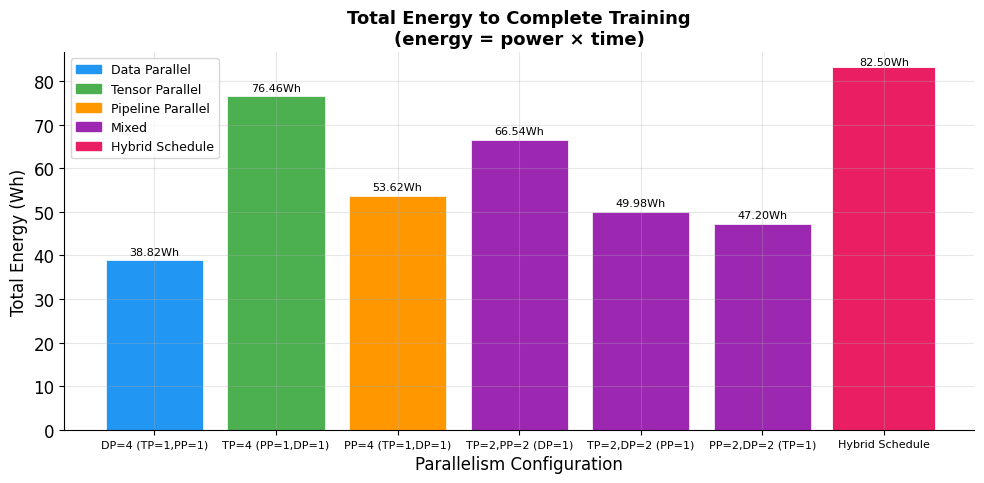

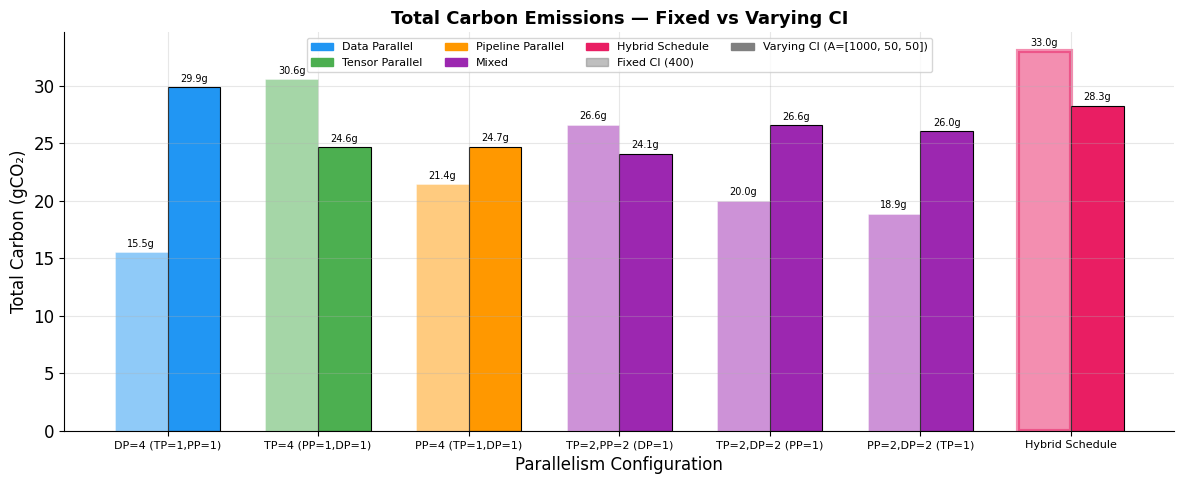

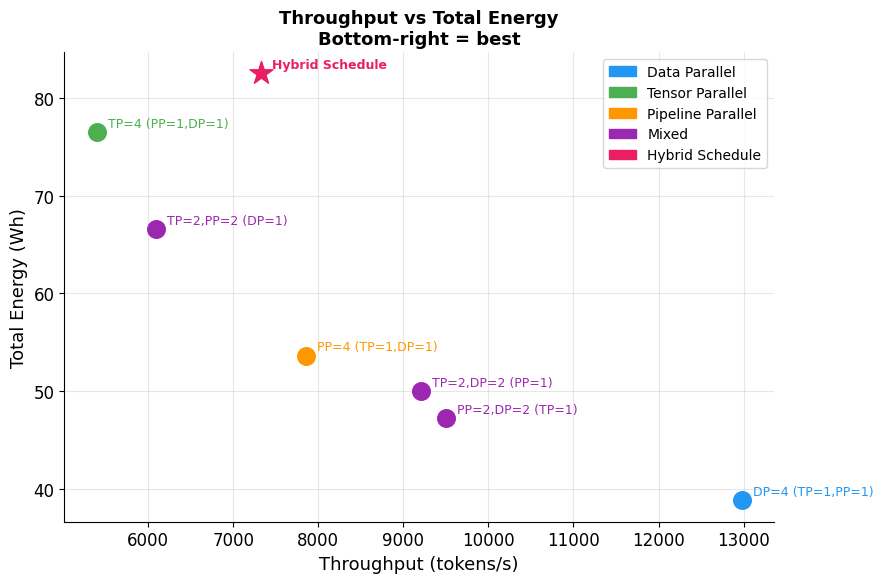

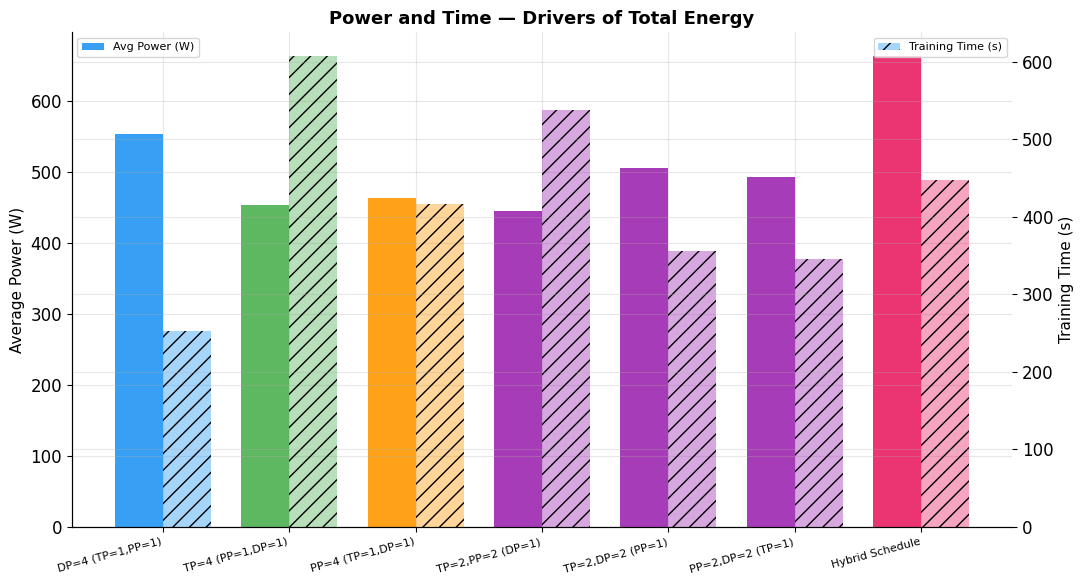

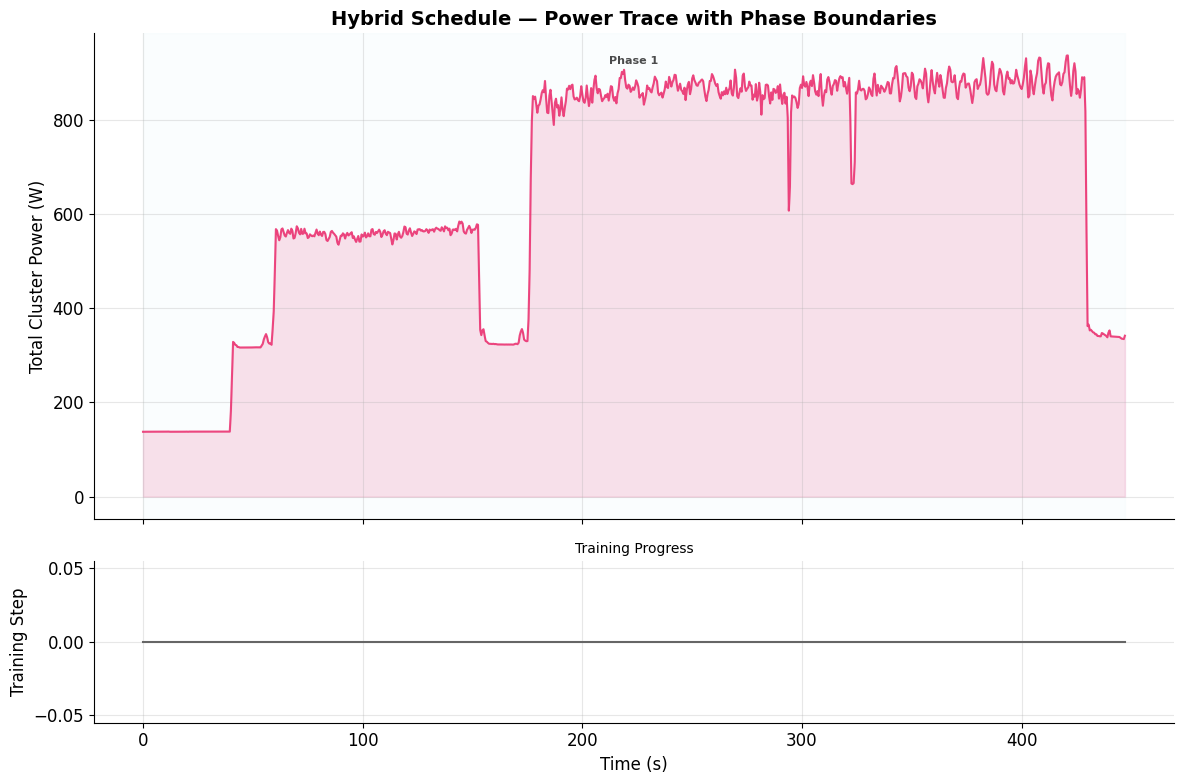

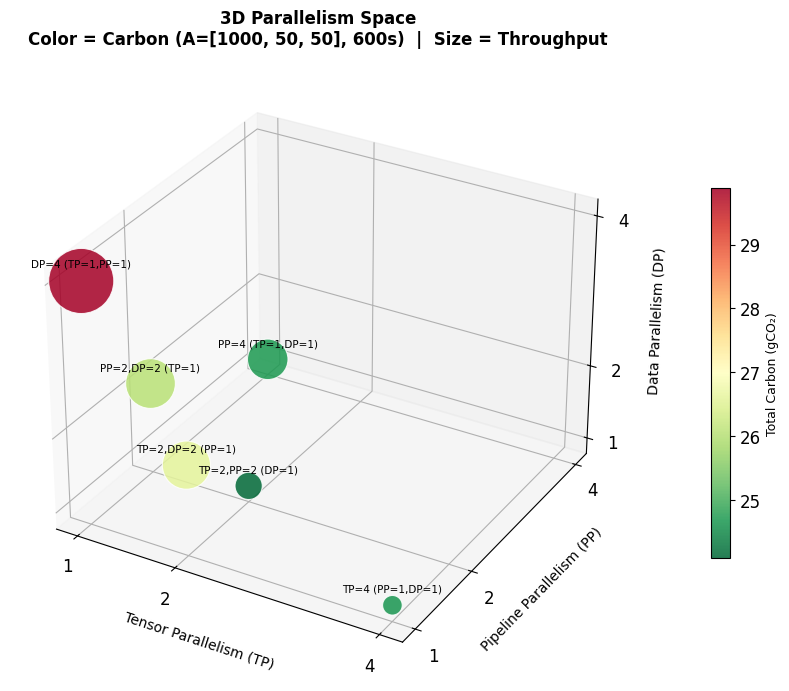


SUMMARY TABLE
          Config     Type  Time(s)  Avg Power(W)  Total Energy(Wh)  Carbon Fixed@400(gCO₂)  Carbon Vary A=[1000, 50, 50](gCO₂)  Throughput(tok/s)
DP=4 (TP=1,PP=1)   Static    252.5         553.5             38.82                   15.53                               29.88            12977.4
TP=4 (PP=1,DP=1)   Static    607.5         453.1             76.46                   30.58                               24.64             5393.9
PP=4 (TP=1,DP=1)   Static    417.0         462.9             53.62                   21.45                               24.70             7858.0
TP=2,PP=2 (DP=1)   Static    537.5         445.6             66.54                   26.61                               24.10             6096.4
TP=2,DP=2 (PP=1)   Static    356.0         505.4             49.98                   19.99                               26.58             9204.5
PP=2,DP=2 (TP=1)   Static    345.0         492.5             47.20                   18.88                   

In [13]:
# Visualization Notebook
#
# Analyzes power logs from 3D parallelism benchmarks.
# Includes both static configs AND the hybrid/schedule strategy.
#
# Key insight: for a fixed training job, what matters is TOTAL energy
# and carbon (energy = power × time), not per-token rates.
#
# ── Audit fixes applied ─────────────────────────────────────
# FIX 1 (critical): CI schedule is now wall-clock-based.
#        A defines CI over a fixed real-time window, not per-config
#        fractions.  All configs start at t=0 and share the same
#        CI timeline, so faster configs do NOT artificially benefit
#        from "reaching" clean grid sooner.
#
# FIX 2 (visual):   CI period annotations now match the actual
#        wall-clock boundaries used in computation.
#
# FIX 3 (minor):    Removed redundant carbon column from summary.
#        Section 5 computes both fixed and varying carbon directly.

# =====================================================================
# 1) Imports and Plot Style
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3",
    "tp": "#4CAF50",
    "pp": "#FF9800",
    "mixed": "#9C27B0",
    "schedule": "#E91E63",
}

# =====================================================================
# 2) Configuration
# =====================================================================
BASE = os.getcwd()
MODEL_NAME = "gpt2"
DATA_DIR = os.path.join(BASE, "power_logs", MODEL_NAME)
PLOTS_DIR = os.path.join(BASE, "plots", MODEL_NAME)
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Reading power logs from: {DATA_DIR}")
print(f"Saving plots to: {PLOTS_DIR}")

INTERVAL_SECONDS = 0.5
TRAIN_ITERS = 200
GLOBAL_BATCH = 16
SEQ_LEN = 1024

# ── Carbon intensity schedule (wall-clock-based) ─────────────
# A defines CI values over equal-length periods of CI_SCHEDULE_DURATION_S
# seconds of REAL wall-clock time.  Every config shares this timeline.
#
# Example: A = [1000, 400], CI_SCHEDULE_DURATION_S = 600
#   → 0–300 s at 1000 gCO₂/kWh, 300–600 s at 400 gCO₂/kWh
#   A config that finishes at 250 s sees ONLY the dirty period.
#   A config that finishes at 500 s sees 300 s dirty + 200 s clean.
#
# If a config runs LONGER than CI_SCHEDULE_DURATION_S, the last
# CI value in A extends to cover the remainder.

A = [1000, 50, 50]              # CI per period (gCO₂/kWh)
CI_SCHEDULE_DURATION_S = 600 # total wall-clock span of the schedule
CI_FIXED = 400               # baseline constant for comparison

# =====================================================================
# 3) Helper Functions
# =====================================================================

def load_power_csv(path):
    """Load a power CSV with the standard format."""
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if "time_step" not in df.columns:
        df.columns = ["timestamp", "total_power_W",
                       "GPU_0_W", "GPU_1_W", "GPU_2_W", "GPU_3_W"]
        df["time_step"] = 0
    return df


def get_ci_schedule_wallclock(n_samples, interval, A, schedule_duration_s):
    """
    Return per-sample CI array based on WALL-CLOCK time.

    Each sample i corresponds to wall-clock time t = i * interval.
    A divides schedule_duration_s into len(A) equal periods.
    Samples beyond schedule_duration_s get the last CI value in A.

    This ensures all configs share the same CI timeline regardless
    of how fast they finish.
    """
    ci = np.full(n_samples, A[-1], dtype=float)  # default: last CI value
    period_s = schedule_duration_s / len(A)

    for i, c in enumerate(A):
        t_start = i * period_s
        t_end = (i + 1) * period_s
        # Convert time boundaries to sample indices
        idx_start = int(t_start / interval)
        idx_end = int(t_end / interval)
        # Clamp to array bounds
        idx_start = max(0, min(idx_start, n_samples))
        idx_end = max(0, min(idx_end, n_samples))
        ci[idx_start:idx_end] = c

    return ci


def compute_carbon(power_samples, ci_array, interval=0.5):
    """Compute cumulative and total carbon given per-sample CI."""
    energy_kwh = power_samples * interval / 3_600_000
    grams = energy_kwh * ci_array
    return np.cumsum(grams), grams.sum()


# ── Dynamic CI → color mapping ───────────────────────────────
_CI_CMAP = plt.cm.YlOrRd
_CI_NORM = None

def build_ci_norm(A):
    """Call once after A is defined to anchor the colormap."""
    global _CI_NORM
    ci_min, ci_max = min(A), max(A)
    if ci_max == ci_min:
        _CI_NORM = mcolors.Normalize(vmin=ci_min * 0.9, vmax=ci_max * 1.1)
    else:
        _CI_NORM = mcolors.Normalize(vmin=ci_min, vmax=ci_max)

def ci_to_color(ci_val):
    """Map an absolute CI value to a color via the anchored colormap."""
    if _CI_NORM is None:
        raise RuntimeError("Call build_ci_norm(A) before ci_to_color().")
    return _CI_CMAP(_CI_NORM(ci_val))

def ci_to_rgba(ci_val, alpha=0.18):
    """Return RGBA tuple with the given alpha for axvspan use."""
    r, g, b, _ = ci_to_color(ci_val)
    return (r, g, b, alpha)

def ci_label(ci_val, A):
    """Return a human-readable label for a CI value relative to schedule."""
    ci_min, ci_max = min(A), max(A)
    if ci_val == ci_max and ci_val != ci_min:
        return f"{ci_val} g/kWh (high)"
    elif ci_val == ci_min and ci_val != ci_max:
        return f"{ci_val} g/kWh (low)"
    else:
        return f"{ci_val} g/kWh"

build_ci_norm(A)

# ── CI colorbar helper ────────────────────────────────────────
def add_ci_colorbar(fig, ax, A, label="Carbon Intensity (gCO₂/kWh)"):
    """Attach a colorbar showing the CI range used in schedule A."""
    sm = plt.cm.ScalarMappable(cmap=_CI_CMAP, norm=_CI_NORM)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, orientation="vertical",
                      fraction=0.03, pad=0.02, shrink=0.8)
    cb.set_label(label, fontsize=9)
    cb.set_ticks(sorted(set(A)))
    cb.set_ticklabels([ci_label(c, A) for c in sorted(set(A))])
    return cb


def _classify(cfg):
    if cfg["is_schedule"]:
        return "schedule"
    dims_gt1 = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims_gt1 >= 2:
        return "mixed"
    if cfg["tp"] > 1:
        return "tp"
    if cfg["pp"] > 1:
        return "pp"
    return "dp"


def _label(cfg):
    if cfg["is_schedule"]:
        return "Hybrid\nSchedule"
    parts = []
    if cfg["tp"] > 1: parts.append(f"TP={cfg['tp']}")
    if cfg["pp"] > 1: parts.append(f"PP={cfg['pp']}")
    if cfg["dp"] > 1: parts.append(f"DP={cfg['dp']}")
    main = ",".join(parts) if parts else "DP=1"
    others = []
    if cfg["tp"] == 1 and any(c > 1 for c in (cfg["pp"], cfg["dp"])):
        others.append("TP=1")
    if cfg["pp"] == 1 and any(c > 1 for c in (cfg["tp"], cfg["dp"])):
        others.append("PP=1")
    if cfg["dp"] == 1 and any(c > 1 for c in (cfg["tp"], cfg["pp"])):
        others.append("DP=1")
    return f"{main}\n({','.join(others)})" if others else main

# =====================================================================
# 4) Load CSVs and Compute Power Statistics
# =====================================================================

all_possible_configs = {
    "tp1_pp1_dp4": {"tp": 1, "pp": 1, "dp": 4, "file": "tp1_pp1_dp4_power.csv", "is_schedule": False},
    "tp4_pp1_dp1": {"tp": 4, "pp": 1, "dp": 1, "file": "tp4_pp1_dp1_power.csv", "is_schedule": False},
    "tp1_pp4_dp1": {"tp": 1, "pp": 4, "dp": 1, "file": "tp1_pp4_dp1_power.csv", "is_schedule": False},
    "tp2_pp2_dp1": {"tp": 2, "pp": 2, "dp": 1, "file": "tp2_pp2_dp1_power.csv", "is_schedule": False},
    "tp2_pp1_dp2": {"tp": 2, "pp": 1, "dp": 2, "file": "tp2_pp1_dp2_power.csv", "is_schedule": False},
    "tp1_pp2_dp2": {"tp": 1, "pp": 2, "dp": 2, "file": "tp1_pp2_dp2_power.csv", "is_schedule": False},
}

schedule_configs_def = {
    "hybrid_schedule": {
        "tp": None, "pp": None, "dp": None,
        #"file": "schedule_example_schedule_power.csv",
        "file": "elastic_example_schedule_power.csv",
        "is_schedule": True,
    },
}

configs = {}
skipped = []

for name, cfg in {**all_possible_configs, **schedule_configs_def}.items():
    path = os.path.join(DATA_DIR, cfg["file"])
    if not os.path.exists(path):
        skipped.append(name)
        continue
    df = load_power_csv(path)
    if len(df) < 2:
        skipped.append(name)
        continue

    warmup = int(len(df) * 0.2)
    steady = df.iloc[warmup:]

    cfg["avg_power"] = df["total_power_W"].mean()
    cfg["steady_avg_power"] = steady["total_power_W"].mean()
    cfg["peak_power"] = df["total_power_W"].max()
    cfg["df"] = df
    configs[name] = cfg

    sched_tag = " [SCHEDULE]" if cfg["is_schedule"] else ""
    print(
        f"{name}{sched_tag}: avg={cfg['avg_power']:.1f}W  "
        f"steady_avg={cfg['steady_avg_power']:.1f}W  "
        f"peak={cfg['peak_power']:.1f}W  samples={len(df)}"
    )

if skipped:
    print(f"\nSkipped (missing or empty): {', '.join(skipped)}")

static_configs = {k: v for k, v in configs.items() if not v["is_schedule"]}
sched_configs  = {k: v for k, v in configs.items() if v["is_schedule"]}
n_configs = len(configs)

all_configs = []
for name, cfg in configs.items():
    ctype = _classify(cfg)
    label = _label(cfg)
    all_configs.append((label, ctype, cfg))

# =====================================================================
# 5) Compute Metrics for All Configs
# =====================================================================
total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN

print(f"\n{'Label':25s} | {'Time':>7s} | {'Power':>7s} | "
      f"{'Energy':>8s} | {'C_fixed':>8s} | {'C_vary':>8s} | {'Tput':>10s}")
print("-" * 95)

for label, ctype, cfg in all_configs:
    power_samples = cfg["df"]["total_power_W"].to_numpy()
    n = len(power_samples)
    total_time_s = n * INTERVAL_SECONDS
    total_energy_wh = power_samples.sum() * INTERVAL_SECONDS / 3600
    avg_power_w = power_samples.mean()
    tokens_per_sec = total_tokens / total_time_s

    cfg["train_time_s"] = total_time_s
    cfg["total_time_s"] = total_time_s
    cfg["avg_power_w"] = avg_power_w
    cfg["total_energy_wh"] = total_energy_wh
    cfg["tokens_per_sec"] = tokens_per_sec

    # Carbon: fixed CI
    ci_fixed_arr = np.full(n, CI_FIXED)
    _, cfg["carbon_fixed_g"] = compute_carbon(power_samples, ci_fixed_arr)

    # Carbon: wall-clock-based varying CI
    ci_varying_arr = get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A,
                                                CI_SCHEDULE_DURATION_S)
    _, cfg["carbon_varying_g"] = compute_carbon(power_samples, ci_varying_arr)

    tag = " ★" if cfg["is_schedule"] else ""
    print(
        f"{label.replace(chr(10),' '):25s} | {total_time_s:6.1f}s | {avg_power_w:6.1f}W | "
        f"{total_energy_wh:7.2f}Wh | {cfg['carbon_fixed_g']:6.2f}g | "
        f"{cfg['carbon_varying_g']:6.2f}g | "
        f"{tokens_per_sec:8.1f} tok/s{tag}"
    )

# =====================================================================
# 6) Graph 0a: Power Traces Per Config
# =====================================================================
if n_configs > 0:
    ncols = min(3, n_configs)
    nrows = (n_configs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows),
                             sharex=False, sharey=False)
    axes = np.atleast_1d(axes).flatten()

    for ax, (name, cfg) in zip(axes, configs.items()):
        df = cfg["df"].copy()
        warmup_idx = int(len(df) * 0.2)
        x = np.arange(len(df)) * 0.5
        y = df["total_power_W"].to_numpy()

        ax.plot(x[:warmup_idx], y[:warmup_idx], color="#B0BEC5",
                linewidth=1.8, label="Warmup (first 20%)")
        ax.plot(x[warmup_idx:], y[warmup_idx:],
                color=COLORS["schedule"] if cfg["is_schedule"] else "#1976D2",
                linewidth=2.0, label="Steady-state")
        ax.axvline(x[warmup_idx] if warmup_idx < len(x) else x[-1],
                   color="#E53935", linestyle="--", linewidth=1.2)
        ax.axhline(cfg["steady_avg_power"], color="#43A047",
                   linestyle=":", linewidth=1.5)

        if cfg["is_schedule"]:
            title = "Hybrid Schedule"
            steps = df["time_step"].to_numpy()
            for j in range(1, len(steps)):
                if steps[j] < steps[j-1] and steps[j-1] > 0:
                    ax.axvline(x[j], color="#FF9800", linestyle="-.",
                               linewidth=1, alpha=0.7)
        else:
            title = f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"

        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.set_xlabel("Time (s)", fontsize=9)
        ax.set_ylabel("Total Power (W)", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.text(0.02, 0.92, f"steady avg={cfg['steady_avg_power']:.1f}W",
                transform=ax.transAxes, fontsize=8, color="#2E7D32")

    for ax in axes[n_configs:]:
        ax.set_visible(False)

    handles, labels_leg = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc="upper left", ncol=4, fontsize=9, frameon=False)
    fig.suptitle("Power Consumption Per Configuration",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_power_trends.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 7) Graph 0b: Cumulative Carbon (Fixed CI)
# =====================================================================
if n_configs > 0:
    fig, ax = plt.subplots(figsize=(11, 6))
    for name, cfg in configs.items():
        df = cfg["df"].copy()
        x = np.arange(len(df)) * INTERVAL_SECONDS
        grams = (df["total_power_W"].to_numpy() * INTERVAL_SECONDS / 3_600_000) * CI_FIXED
        cum = np.cumsum(grams)

        style = {"linewidth": 3.0, "linestyle": "--"} if cfg["is_schedule"] else {"linewidth": 2.0}
        label = "Hybrid Schedule" if cfg["is_schedule"] else \
                f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"
        color = COLORS["schedule"] if cfg["is_schedule"] else None
        ax.plot(x, cum, label=label, color=color, **style)
        ax.scatter(x[-1], cum[-1], s=45, zorder=3, color=color)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Cumulative Carbon Emissions (gCO₂)", fontsize=12)
    ax.set_title(f"Cumulative Carbon Emissions (Fixed CI = {CI_FIXED} gCO₂/kWh)",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=8, ncol=2, frameon=False)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_carbon_trends.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 8) Time-Varying Carbon Intensity Analysis
# =====================================================================
print("\n" + "=" * 80)
print(f"CARBON SCHEDULE (wall-clock-based):")
print(f"  A = {A} gCO₂/kWh over {CI_SCHEDULE_DURATION_S}s")
period_s = CI_SCHEDULE_DURATION_S / len(A)
for i, c in enumerate(A):
    print(f"  Period {i+1}: {i*period_s:.0f}–{(i+1)*period_s:.0f}s → {ci_label(c, A)}")
print(f"Fixed baseline: {CI_FIXED} gCO₂/kWh")
print("=" * 80)

print(f"\n{'Config':25s} | {'Time':>6s} | {'Fixed CI':>10s} | {'Varying CI':>10s} | {'Δ':>8s}")
print("-" * 70)

for name, cfg in configs.items():
    delta_pct = ((cfg["carbon_varying_g"] - cfg["carbon_fixed_g"])
                 / cfg["carbon_fixed_g"] * 100)

    label = "Hybrid Schedule" if cfg["is_schedule"] else \
            f"TP={cfg['tp']},PP={cfg['pp']},DP={cfg['dp']}"
    print(f"{label:25s} | {cfg['total_time_s']:5.0f}s | "
          f"{cfg['carbon_fixed_g']:8.2f} g | {cfg['carbon_varying_g']:8.2f} g | "
          f"{delta_pct:+6.1f}%")


# ── Helper: annotate CI periods on an axes ───────────────────
def annotate_ci_periods(ax, A, schedule_duration_s, y_label_frac=0.04):
    """
    Draw color-shaded period bands at FIXED wall-clock boundaries.
    These match the actual CI applied to every config's power samples.
    """
    period_s = schedule_duration_s / len(A)
    ylo, yhi = ax.get_ylim()
    y_text = ylo + (yhi - ylo) * y_label_frac
    for i, c in enumerate(A):
        x0 = i * period_s
        x1 = (i + 1) * period_s
        ax.axvspan(x0, x1, alpha=0.18, color=ci_to_color(c), zorder=0)
        ax.text((x0 + x1) / 2, y_text, ci_label(c, A),
                ha="center", va="bottom", fontsize=9,
                fontweight="bold", color=ci_to_color(c), alpha=0.85)
    # If any config extends beyond the schedule, shade the extension
    xlim = ax.get_xlim()
    if xlim[1] > schedule_duration_s:
        ax.axvspan(schedule_duration_s, xlim[1], alpha=0.10,
                   color=ci_to_color(A[-1]), zorder=0)
        ax.text((schedule_duration_s + xlim[1]) / 2, y_text,
                f"{A[-1]} g/kWh\n(extended)",
                ha="center", va="bottom", fontsize=8,
                color=ci_to_color(A[-1]), alpha=0.7)


# ── Side-by-side: Fixed CI vs Varying CI ─────────────────────
if n_configs > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for ax, use_varying in zip(axes, [False, True]):
        for name, cfg in configs.items():
            power = cfg["df"]["total_power_W"].to_numpy()
            n = len(power)
            if use_varying:
                ci = get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A,
                                               CI_SCHEDULE_DURATION_S)
            else:
                ci = np.full(n, CI_FIXED)
            cum, _ = compute_carbon(power, ci)
            x = np.arange(n) * INTERVAL_SECONDS

            style = {"linewidth": 3.0, "linestyle": "--"} if cfg["is_schedule"] else {"linewidth": 2.0}
            lbl = "Hybrid Schedule" if cfg["is_schedule"] else \
                  f"TP={cfg['tp']},PP={cfg['pp']},DP={cfg['dp']}"
            color = COLORS["schedule"] if cfg["is_schedule"] else None
            ax.plot(x, cum, label=lbl, color=color, **style)
            ax.scatter(x[-1], cum[-1], s=45, zorder=3, color=color)

        if use_varying:
            # Annotations at fixed wall-clock boundaries
            annotate_ci_periods(ax, A, CI_SCHEDULE_DURATION_S)
            ax.set_title(f"Varying CI  (A = {A}, {CI_SCHEDULE_DURATION_S}s window)",
                         fontsize=12, fontweight="bold")
            add_ci_colorbar(fig, ax, A)
        else:
            ax.set_title(f"Fixed CI  ({CI_FIXED} gCO₂/kWh)",
                         fontsize=12, fontweight="bold")

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Cumulative CO₂ (g)")
        ax.legend(fontsize=7, ncol=2, frameon=False)

    plt.suptitle(
        f"Impact of Time-Varying Carbon Intensity\n"
        f"Fixed = {CI_FIXED} gCO₂/kWh  |  Schedule A = {A} over {CI_SCHEDULE_DURATION_S}s",
        fontsize=13, fontweight="bold", y=1.03,
    )
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_carbon_varying_ci.png"),
                dpi=150, bbox_inches="tight")
    plt.show()


# ── Bar chart: fixed vs varying ──────────────────────────────
if n_configs > 0:
    labels_ci   = []
    fixed_vals  = []
    varying_vals = []
    bar_colors  = []

    for name, cfg in configs.items():
        labels_ci.append("Hybrid\nSchedule" if cfg["is_schedule"] else
                         f"TP={cfg.get('tp','?')}\nPP={cfg.get('pp','?')}\nDP={cfg.get('dp','?')}")
        fixed_vals.append(cfg["carbon_fixed_g"])
        varying_vals.append(cfg["carbon_varying_g"])
        bar_colors.append(COLORS["schedule"] if cfg["is_schedule"] else "#546E7A")

    x = np.arange(len(labels_ci))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, fixed_vals, width, color=bar_colors,
           alpha=0.5, label=f"Fixed CI  ({CI_FIXED} gCO₂/kWh)")
    ax.bar(x + width/2, varying_vals, width, color=bar_colors,
           edgecolor="black", linewidth=0.5,
           label=f"Varying CI  (A = {A}, {CI_SCHEDULE_DURATION_S}s)")

    ax.set_ylabel("Total Carbon (gCO₂)", fontsize=12)
    ax.set_title(f"Fixed vs Time-Varying Carbon Intensity",
                 fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels_ci, fontsize=8)
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_carbon_fixed_vs_varying.png"),
                dpi=150, bbox_inches="tight")
    plt.show()


# ── Theoretical optimal ─────────────────────────────────────
static_only = {k: v for k, v in configs.items() if not v["is_schedule"]}
if static_only:
    fastest      = max(static_only.items(), key=lambda kv: kv[1].get("tokens_per_sec", 0))
    lowest_power = min(static_only.items(), key=lambda kv: kv[1]["steady_avg_power"])

    ci_sorted = sorted(set(A))
    ci_median = ci_sorted[len(ci_sorted) // 2] if len(ci_sorted) > 2 else (min(A) + max(A)) / 2

    print(f"\nOptimal carbon-aware schedule for A = {A}:")
    for i, ci in enumerate(A):
        if ci >= ci_median:
            pick   = lowest_power
            reason = "low power — minimize emissions during dirty grid"
        else:
            pick   = fastest
            reason = "max throughput — finish quickly during clean grid"
        print(f"  Period {i+1} ({ci_label(ci, A)}) → {pick[0]} ({reason})")

# =====================================================================
# 9) Graphs 1-3: Single-axis Power vs DP/TP/PP (static only)
# =====================================================================
def _plot_single_axis(dim_name, color_key, dim_key, graph_num):
    data = []
    for name, cfg in static_configs.items():
        data.append((cfg[dim_key], cfg["avg_power"], name))
    if len(data) < 2:
        return
    data.sort()
    xs, ys, _ = zip(*data)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(xs, ys, "o-", color=COLORS[color_key], linewidth=2.5,
            markersize=10, markerfacecolor="white", markeredgewidth=2.5)
    for x, y in zip(xs, ys):
        ax.annotate(f"{y:.1f}W", (x, y), textcoords="offset points",
                    xytext=(8, 6), fontsize=10, color=COLORS[color_key])
    ax.set_xlabel(f"{dim_name} Parallelism Degree", fontsize=13)
    ax.set_ylabel("Total Cluster Power (W)", fontsize=13)
    ax.set_title(f"{dim_name} Parallelism vs Power", fontsize=14, fontweight="bold")
    ax.set_xticks(sorted(set(xs)))
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f"graph{graph_num}_{dim_key}_vs_power.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

_plot_single_axis("Data",     "dp", "dp", 1)
_plot_single_axis("Tensor",   "tp", "tp", 2)
_plot_single_axis("Pipeline", "pp", "pp", 3)

# =====================================================================
# 10) Graph 4: Power vs Total Training Time
# =====================================================================
patches = [
    mpatches.Patch(color=COLORS["dp"],       label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"],       label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"],       label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"],    label="Mixed"),
    mpatches.Patch(color=COLORS["schedule"], label="Hybrid Schedule"),
]

if all_configs:
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, ctype, cfg in all_configs:
        marker = "*" if cfg["is_schedule"] else "o"
        size   = 250  if cfg["is_schedule"] else 150
        ax.scatter(cfg["train_time_s"], cfg["avg_power_w"],
                   color=COLORS[ctype], s=size, zorder=3, marker=marker)
        ax.annotate(label.replace("\n", " "),
                    (cfg["train_time_s"], cfg["avg_power_w"]),
                    textcoords="offset points", xytext=(8, 4),
                    fontsize=9, color=COLORS[ctype],
                    fontweight="bold" if cfg["is_schedule"] else "normal")
    ax.legend(handles=patches, fontsize=10, loc="best")
    ax.set_xlabel("Total Training Time (s)", fontsize=13)
    ax.set_ylabel("Average Cluster Power (W)", fontsize=13)
    ax.set_title("Power vs Training Time\nTop-right = worst",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph4_power_vs_time.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 11) Graphs 5-9: Bar Charts
# =====================================================================
if all_configs:
    labels_bar      = [c[0].replace("\n", " ") for c in all_configs]
    colors_bar      = [COLORS[c[1]] for c in all_configs]
    time_vals       = [c[2]["train_time_s"]     for c in all_configs]
    energy_vals     = [c[2]["total_energy_wh"]  for c in all_configs]
    carbon_fixed    = [c[2]["carbon_fixed_g"]   for c in all_configs]
    carbon_varying  = [c[2]["carbon_varying_g"] for c in all_configs]
    throughput_vals = [c[2]["tokens_per_sec"]   for c in all_configs]
    is_sched        = [c[2]["is_schedule"]      for c in all_configs]

    edge_colors = ["#E91E63" if s else "white" for s in is_sched]
    edge_widths = [3 if s else 0.5 for s in is_sched]

    # Graph 5: Total training time
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels_bar, time_vals, color=colors_bar,
                  edgecolor=edge_colors, linewidth=edge_widths)
    for bar, val in zip(bars, time_vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(time_vals) * 0.01,
                f"{val:.1f}s", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=9)
    ax.set_ylabel("Total Training Time (s)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Training Time by Strategy", fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph5_total_time.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 6: Total energy
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels_bar, energy_vals, color=colors_bar,
                  edgecolor=edge_colors, linewidth=edge_widths)
    for bar, val in zip(bars, energy_vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(energy_vals) * 0.01,
                f"{val:.2f}Wh", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=9)
    ax.set_ylabel("Total Energy (Wh)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Energy to Complete Training\n(energy = power × time)",
                 fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph6_total_energy.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 7: Total carbon — both fixed and varying side by side
    x = np.arange(len(labels_bar))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(x - width/2, carbon_fixed, width, color=colors_bar,
           alpha=0.5, edgecolor=edge_colors, linewidth=edge_widths,
           label=f"Fixed CI ({CI_FIXED} gCO₂/kWh)")
    ax.bar(x + width/2, carbon_varying, width, color=colors_bar,
           edgecolor="black", linewidth=0.8,
           label=f"Varying CI (A={A}, {CI_SCHEDULE_DURATION_S}s)")
    for xi, vf, vv in zip(x, carbon_fixed, carbon_varying):
        ax.text(xi - width/2, vf + max(carbon_varying) * 0.01,
                f"{vf:.1f}g", ha="center", va="bottom", fontsize=7)
        ax.text(xi + width/2, vv + max(carbon_varying) * 0.01,
                f"{vv:.1f}g", ha="center", va="bottom", fontsize=7)
    ax.legend(handles=patches + [
        mpatches.Patch(color="gray", alpha=0.5, label=f"Fixed CI ({CI_FIXED})"),
        mpatches.Patch(color="gray", alpha=1.0, label=f"Varying CI (A={A})"),
    ], fontsize=8, ncol=4)
    ax.set_ylabel("Total Carbon (gCO₂)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Carbon Emissions — Fixed vs Varying CI",
                 fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels_bar, fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph7_total_carbon.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 8: Throughput vs total energy (Pareto)
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, ctype, cfg in all_configs:
        marker = "*" if cfg["is_schedule"] else "o"
        size   = 300  if cfg["is_schedule"] else 160
        ax.scatter(cfg["tokens_per_sec"], cfg["total_energy_wh"],
                   color=COLORS[ctype], s=size, zorder=3, marker=marker)
        ax.annotate(label.replace("\n", " "),
                    (cfg["tokens_per_sec"], cfg["total_energy_wh"]),
                    textcoords="offset points", xytext=(8, 4),
                    fontsize=9, color=COLORS[ctype],
                    fontweight="bold" if cfg["is_schedule"] else "normal")
    ax.legend(handles=patches, fontsize=10, loc="best")
    ax.set_xlabel("Throughput (tokens/s)", fontsize=13)
    ax.set_ylabel("Total Energy (Wh)", fontsize=13)
    ax.set_title("Throughput vs Total Energy\nBottom-right = best",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph8_throughput_vs_energy.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 9: Grouped power + time bars
    x = np.arange(len(labels_bar))
    width = 0.38
    fig, ax1 = plt.subplots(figsize=(11, 6))
    power_vals = [c[2]["avg_power_w"] for c in all_configs]
    ax1.bar(x - width / 2, power_vals, width, color=colors_bar, alpha=0.9, label="Avg Power (W)")
    ax1.set_ylabel("Average Power (W)", fontsize=11)
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels_bar, rotation=15, ha="right", fontsize=8)

    ax2 = ax1.twinx()
    ax2.bar(x + width / 2, time_vals, width, color=colors_bar, alpha=0.4,
            hatch="//", label="Training Time (s)")
    ax2.set_ylabel("Training Time (s)", fontsize=11)

    ax1.set_title("Power and Time — Drivers of Total Energy",
                  fontsize=13, fontweight="bold")
    ax1.legend(loc="upper left", fontsize=8)
    ax2.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph9_power_and_time.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 12) Schedule-specific Power Trace with Phase Annotations
# =====================================================================
for name, cfg in sched_configs.items():
    df    = cfg["df"].copy()
    x     = np.arange(len(df)) * INTERVAL_SECONDS
    y     = df["total_power_W"].to_numpy()
    steps = df["time_step"].to_numpy()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 1]})

    ax1.plot(x, y, color=COLORS["schedule"], linewidth=1.5, alpha=0.8)
    ax1.fill_between(x, y, alpha=0.15, color=COLORS["schedule"])
    ax1.set_ylabel("Total Cluster Power (W)", fontsize=12)
    ax1.set_title("Hybrid Schedule — Power Trace with Phase Boundaries",
                  fontsize=14, fontweight="bold")

    phase_colors = ["#E3F2FD", "#E8F5E9", "#FFF3E0", "#F3E5F5",
                    "#FCE4EC", "#E0F7FA", "#FFF9C4", "#F3E5F5"]
    boundaries = [0]
    for j in range(1, len(steps)):
        if steps[j] < steps[j-1] and steps[j-1] > 0:
            boundaries.append(j)
    boundaries.append(len(df))

    for p_idx in range(len(boundaries) - 1):
        s_idx = boundaries[p_idx]
        e_idx = boundaries[p_idx + 1]
        if s_idx < len(x) and e_idx <= len(x):
            ax1.axvspan(x[s_idx], x[min(e_idx - 1, len(x) - 1)],
                        alpha=0.15, color=phase_colors[p_idx % len(phase_colors)])
            mid_x = (x[s_idx] + x[min(e_idx - 1, len(x) - 1)]) / 2
            ax1.text(mid_x, ax1.get_ylim()[1] * 0.95, f"Phase {p_idx + 1}",
                     ha="center", va="top", fontsize=8, fontweight="bold", alpha=0.7)

    ax2.plot(x, steps, color="#666", linewidth=1.5)
    ax2.set_xlabel("Time (s)", fontsize=12)
    ax2.set_ylabel("Training Step", fontsize=12)
    ax2.set_title("Training Progress", fontsize=10)

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_schedule_detailed.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 13) 3D Parallelism Space (static configs only)
# =====================================================================
static_all = [(l, c, cfg) for l, c, cfg in all_configs if not cfg["is_schedule"]]

if len(static_all) >= 2:
    tp_vals        = [c[2]["tp"]               for c in static_all]
    pp_vals        = [c[2]["pp"]               for c in static_all]
    dp_vals        = [c[2]["dp"]               for c in static_all]
    carbon_vals_3d = [c[2]["carbon_varying_g"] for c in static_all]
    toks_vals      = [c[2]["tokens_per_sec"]   for c in static_all]
    lbls           = [c[0].replace("\n", " ")  for c in static_all]

    c_min, c_max = min(carbon_vals_3d), max(carbon_vals_3d)
    t_min, t_max = min(toks_vals), max(toks_vals)
    sizes = [200 + 2000 * (t - t_min) / (t_max - t_min + 1e-9) for t in toks_vals]

    fig = plt.figure(figsize=(11, 8))
    ax  = fig.add_subplot(111, projection="3d")
    sc  = ax.scatter(tp_vals, pp_vals, dp_vals, c=carbon_vals_3d, cmap=cm.RdYlGn_r,
                     s=sizes, alpha=0.85, edgecolors="white", linewidths=0.8,
                     vmin=c_min, vmax=c_max)
    for tp, pp, dp, lbl in zip(tp_vals, pp_vals, dp_vals, lbls):
        ax.text(tp, pp, dp + 0.15, lbl, fontsize=7.5, ha="center", va="bottom")

    ax.set_xlabel("Tensor Parallelism (TP)",   fontsize=10, labelpad=8)
    ax.set_ylabel("Pipeline Parallelism (PP)", fontsize=10, labelpad=8)
    ax.set_zlabel("Data Parallelism (DP)",     fontsize=10, labelpad=8)
    ax.set_xticks([1, 2, 4]); ax.set_yticks([1, 2, 4]); ax.set_zticks([1, 2, 4])
    ax.set_title(
        f"3D Parallelism Space\n"
        f"Color = Carbon (A={A}, {CI_SCHEDULE_DURATION_S}s)  |  Size = Throughput",
        fontsize=12, fontweight="bold", pad=15,
    )
    fig.colorbar(sc, ax=ax, pad=0.1, shrink=0.6).set_label("Total Carbon (gCO₂)", fontsize=9)
    plt.savefig(os.path.join(PLOTS_DIR, "graph10_3d_carbon.png"), dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 14) Summary Table
# =====================================================================
if all_configs:
    summary_rows = []
    for label, _, cfg in all_configs:
        summary_rows.append({
            "Config":               label.replace("\n", " "),
            "Type":                 "Schedule" if cfg["is_schedule"] else "Static",
            "Time(s)":              round(cfg["train_time_s"], 1),
            "Avg Power(W)":         round(cfg["avg_power_w"], 1),
            "Total Energy(Wh)":     round(cfg["total_energy_wh"], 2),
            f"Carbon Fixed@{CI_FIXED}(gCO₂)":   round(cfg["carbon_fixed_g"], 2),
            f"Carbon Vary A={A}(gCO₂)":          round(cfg["carbon_varying_g"], 2),
            "Throughput(tok/s)":    round(cfg["tokens_per_sec"], 1),
        })

    summary_df = pd.DataFrame(summary_rows)
    print("\n" + "=" * 100)
    print("SUMMARY TABLE")
    print("=" * 100)
    print(summary_df.to_string(index=False))
    print()

    summary_df.to_csv(os.path.join(PLOTS_DIR, "summary_table.csv"), index=False)
    print(f"Saved to: {os.path.join(PLOTS_DIR, 'summary_table.csv')}")